# 01 · Build the Sentinel-1 → WorldCover dataset

**Input:** Sentinel-1 GRD (IW, VV + VH), monthly median composites for every month of 2021
**Labels:** ESA WorldCover v200 (2021), merged from 11 to 6 classes (see `config.py`)
**Source:** Google Earth Engine (`COPERNICUS/S1_GRD`, `ESA/WorldCover/v200`)

For each of ~50 European regions (7.68 km × 7.68 km at 10 m) this notebook downloads:
- `s1.npy`  → `(12, 2, 768, 768)` float16, VV and VH in dB, NaN where no data
- `label.npy` → `(768, 768)` uint8 merged WorldCover classes (255 = ignore)
- `meta.json` → grid, split, number of S1 scenes per month

Regions are assigned to train, val and test **as whole regions** to avoid spatial leakage between splits.

Why all 12 months against one label? WorldCover is an annual map. Training on every month teaches the model season-invariant radar features, which is exactly what the 12-month prototype needs.

In [1]:
import sys, json, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

ROOT = Path.cwd() if Path("config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import config as C
import s1_data as S
from train_utils import load_regions, compute_norm_stats, class_counts

DATA_DIR = ROOT / "data"
REG_DIR = DATA_DIR / "regions"
REG_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: F:\Downloads\Deep Learning\Project\s1-lulc


## 1 · Connect to Earth Engine
Set `EE_PROJECT` to your Google Cloud project ID that is registered for Earth Engine (noncommercial use is free). The first run opens a browser window to authenticate.

In [2]:
EE_PROJECT = "mesmerizing-app-316813"   # <-- change this
S.init_ee(EE_PROJECT)
import ee
print("Earth Engine OK:", ee.String("hello").getInfo())

Earth Engine OK: hello


## 2 · Regions and splits

split
train    40
val       7
test      6


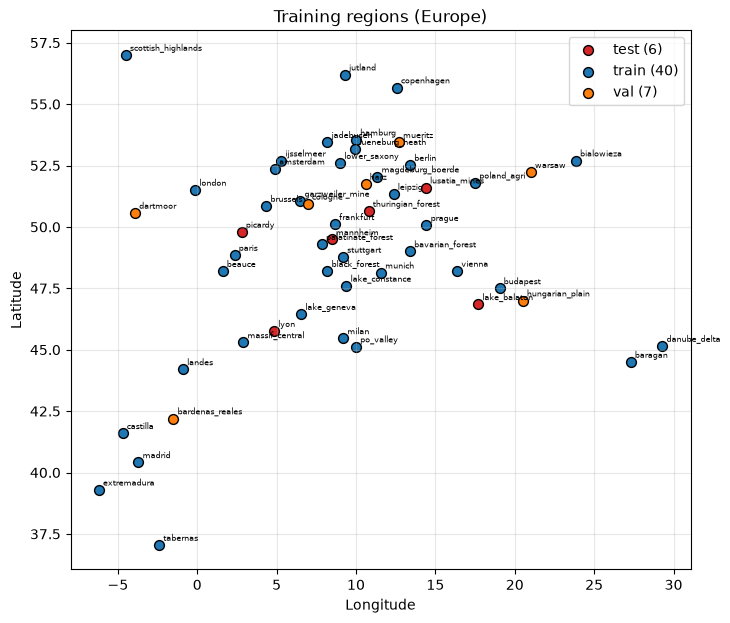

In [3]:
regions_df = pd.DataFrame(C.REGIONS, columns=["name", "lat", "lon", "split"])
print(regions_df["split"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 7))
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}
for split, g in regions_df.groupby("split"):
    ax.scatter(g.lon, g.lat, c=colors[split], label=f"{split} ({len(g)})", s=50, edgecolor="k")
for _, r in regions_df.iterrows():
    ax.annotate(r["name"], (r.lon, r.lat), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title("Training regions (Europe)")
ax.legend(); ax.grid(alpha=.3)
plt.show()

## 3 · Download
One Earth Engine request per region-month (768 × 768 × 2 bands ≈ 4.7 MB, well below the request limit). Requests run in parallel threads. The cell is **resumable**: regions that already have all files are skipped, so you can re-run it after an interruption.

In [4]:
YEAR = C.LABEL_YEAR
N_WORKERS = 8

def download_region(name, lat, lon, split):
    out = REG_DIR / name
    if (out / "meta.json").exists():
        return name, "skipped"
    out.mkdir(exist_ok=True)
    grid = S.make_grid(lat, lon, C.REGION_SIZE_PX)
    label = S.fetch_worldcover(grid)
    s1 = np.full((12, 2, grid.size_px, grid.size_px), np.nan, dtype=np.float16)
    scenes = []
    for m in C.MONTHS:
        arr, n = S.fetch_s1_month(grid, YEAR, m)
        s1[m - 1] = arr.astype(np.float16)
        scenes.append(n)
    np.save(out / "s1.npy", s1)
    np.save(out / "label.npy", label)
    meta = {"name": name, "lat": lat, "lon": lon, "split": split, "year": YEAR,
            "grid": grid.to_dict(), "scenes_per_month": scenes}
    (out / "meta.json").write_text(json.dumps(meta, indent=2))  # written last = completion marker
    return name, f"ok, scenes per month {scenes}"

t0 = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    futures = [ex.submit(download_region, *r) for r in C.REGIONS]
    for f in as_completed(futures):
        try:
            name, status = f.result()
            print(f"{name:20s} {status}")
        except Exception as e:
            print("FAILED:", e)
print(f"Done in {(time.time() - t0) / 60:.1f} min")

stuttgart            ok, scenes per month [11, 7, 11, 15, 15, 14, 16, 13, 15, 15, 15, 13]
mannheim             ok, scenes per month [13, 11, 13, 15, 15, 15, 15, 14, 15, 15, 15, 13]
hamburg              ok, scenes per month [22, 21, 22, 23, 22, 22, 21, 21, 22, 24, 22, 18]
cologne              ok, scenes per month [21, 18, 20, 20, 21, 18, 20, 20, 20, 21, 20, 17]
berlin               ok, scenes per month [22, 21, 23, 21, 25, 25, 26, 26, 24, 27, 23, 22]
leipzig              ok, scenes per month [20, 21, 22, 22, 23, 23, 23, 23, 22, 24, 23, 19]
munich               ok, scenes per month [19, 15, 21, 24, 26, 25, 25, 25, 24, 27, 25, 21]
frankfurt            ok, scenes per month [20, 17, 20, 20, 20, 19, 20, 18, 20, 20, 20, 17]
lyon                 ok, scenes per month [19, 18, 21, 20, 19, 18, 19, 20, 20, 20, 20, 19]
paris                ok, scenes per month [15, 12, 15, 15, 14, 14, 16, 16, 15, 14, 15, 14]
amsterdam            ok, scenes per month [20, 17, 21, 20, 20, 18, 20, 21, 20, 21, 20, 18]


## 4 · Quality checks

In [5]:
regions = load_regions(DATA_DIR)
rows = []
for r in regions:
    valid = [float(np.isfinite(r["s1"][t, 0]).mean()) for t in range(12)]
    rows.append({"region": r["name"], "split": r["split"],
                 "min_scenes": min(r["meta"]["scenes_per_month"]),
                 "mean_valid_%": 100 * np.mean(valid),
                 "label_ignored_%": 100 * (r["label"] == C.IGNORE_INDEX).mean()})
qa = pd.DataFrame(rows).sort_values("region")
print(f"{len(regions)} regions loaded")
qa.round(1)

53 regions loaded


,region,split,min_scenes,mean_valid_%,label_ignored_%
0,amsterdam,train,17,100.0,0.0
1,baragan,train,24,100.0,0.0
2,bardenas_reales,val,18,100.0,0.0
3,bavarian_forest,train,12,100.0,0.0
4,beauce,train,17,100.0,0.0
5,berlin,train,21,100.0,0.0
6,bialowieza,train,17,100.0,0.0
7,black_forest,train,17,100.0,0.0
8,brussels,train,17,100.0,0.0
9,budapest,train,8,100.0,0.0


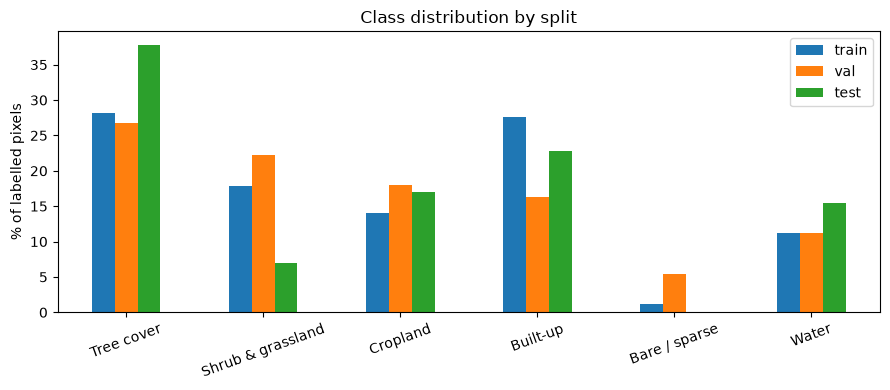

,train,val,test
Tree cover,28.18,26.74,37.82
Shrub & grassland,17.83,22.31,6.95
Cropland,13.98,17.95,16.99
Built-up,27.62,16.30,22.75
Bare / sparse,1.20,5.46,0.09
Water,11.19,11.25,15.40


In [6]:
# Class distribution per split (pixel share) — shows the class imbalance the loss must handle
dist = {}
for split in ["train", "val", "test"]:
    cnt = class_counts([r for r in regions if r["split"] == split])
    dist[split] = 100 * cnt / cnt.sum()
dist = pd.DataFrame(dist, index=C.CLASS_NAMES)
ax = dist.plot.bar(figsize=(9, 4), rot=20)
ax.set_ylabel("% of labelled pixels"); ax.set_title("Class distribution by split")
plt.tight_layout(); plt.show()
dist.round(2)

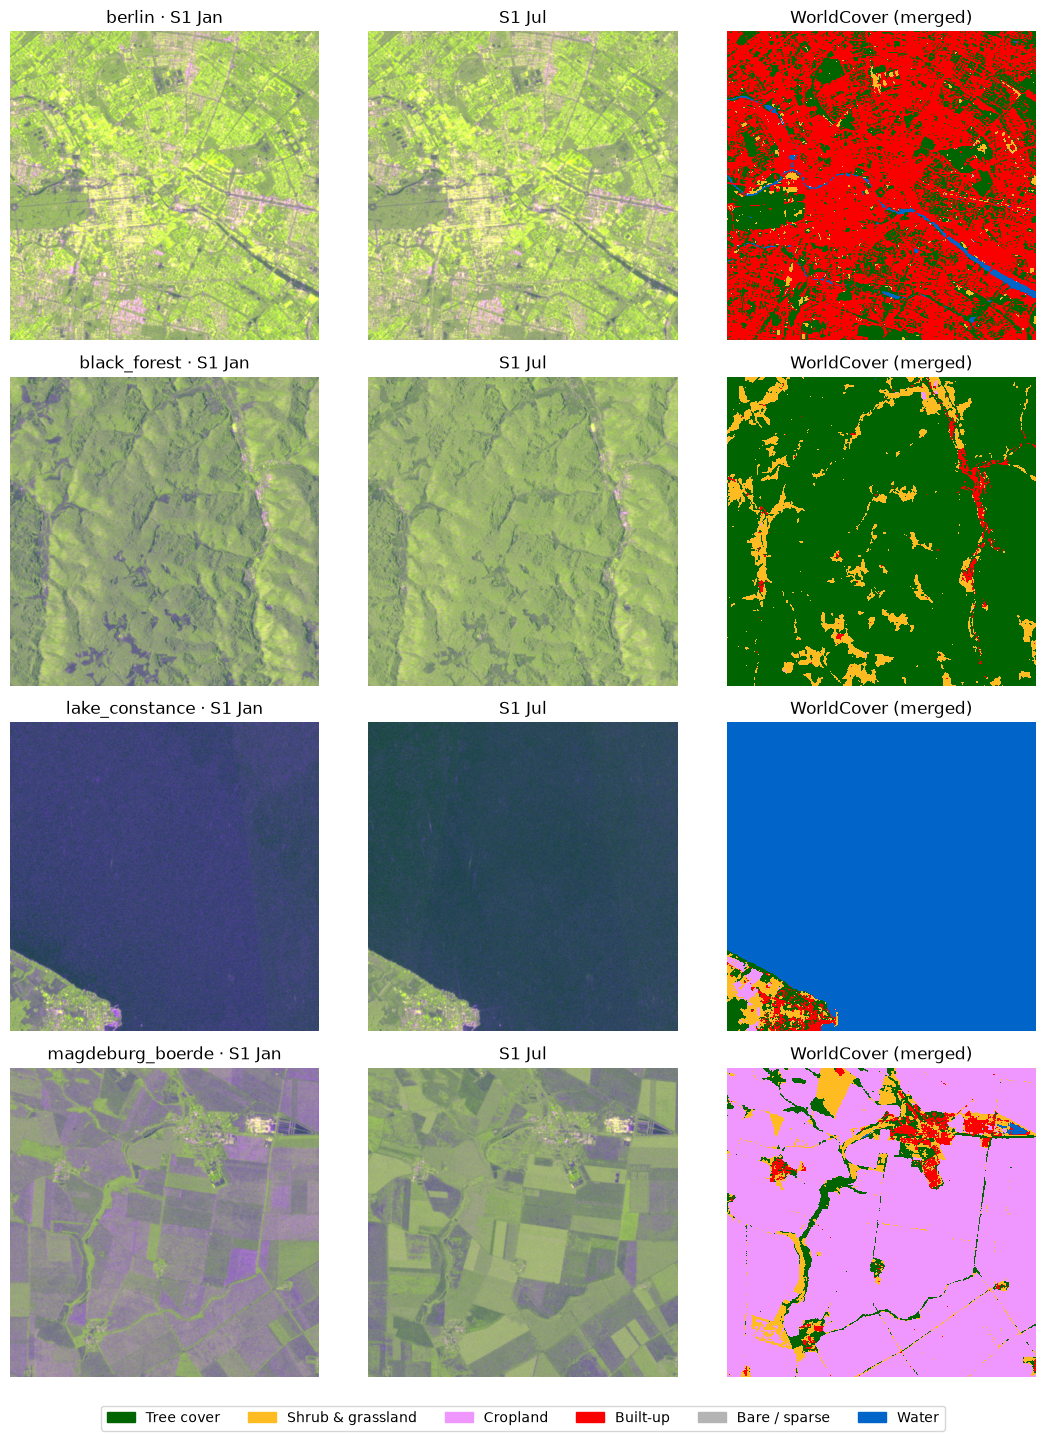

In [7]:
# Visual check: radar composite vs WorldCover label for a few regions (January and July)
cmap = ListedColormap(C.CLASS_COLORS)

def s1_rgb(s1_month):
    # False colour: R = VV, G = VH, B = VV - VH, each stretched to 0..1
    f = S.make_features(s1_month.astype(np.float32))
    rgb = np.zeros(f.shape[1:] + (3,), dtype=np.float32)
    for i, name in enumerate(C.INPUT_CHANNELS):
        lo, hi = C.DB_CLIP[name]
        rgb[..., i] = (f[i] - lo) / (hi - lo)
    return np.nan_to_num(np.clip(rgb, 0, 1))

show = [r for r in regions if r["name"] in ("berlin", "magdeburg_boerde", "black_forest", "lake_constance")]
fig, axes = plt.subplots(len(show), 3, figsize=(11, 3.6 * len(show)))
for row, r in zip(np.atleast_2d(axes), show):
    row[0].imshow(s1_rgb(r["s1"][0])); row[0].set_title(f"{r['name']} · S1 Jan")
    row[1].imshow(s1_rgb(r["s1"][6])); row[1].set_title("S1 Jul")
    lab = np.ma.masked_equal(r["label"], C.IGNORE_INDEX)
    row[2].imshow(lab, cmap=cmap, vmin=0, vmax=C.NUM_CLASSES - 1, interpolation="nearest")
    row[2].set_title("WorldCover (merged)")
    for a in row: a.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in C.CLASS_COLORS]
fig.legend(handles, C.CLASS_NAMES, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

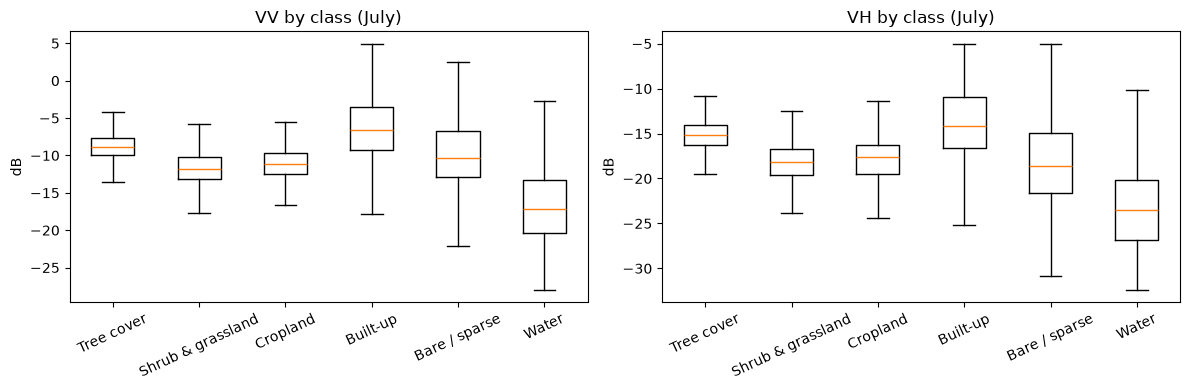

In [8]:
# Radar signatures per class (training regions, July) — shows which classes radar separates well
train_regions = [r for r in regions if r["split"] == "train"]
rng = np.random.default_rng(0)
vals = {k: [] for k in range(C.NUM_CLASSES)}
for r in train_regions:
    f = S.make_features(r["s1"][6].astype(np.float32))
    for k in range(C.NUM_CLASSES):
        m = (r["label"] == k) & np.isfinite(f).all(0)
        idx = np.flatnonzero(m.ravel())
        if idx.size:
            idx = rng.choice(idx, min(2000, idx.size), replace=False)
            vals[k].append(f.reshape(3, -1)[:, idx])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ch, ax in zip([0, 1], axes):
    data = [np.concatenate(vals[k], 1)[ch] if vals[k] else np.array([np.nan]) for k in range(C.NUM_CLASSES)]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, C.NUM_CLASSES + 1), C.CLASS_NAMES, rotation=25)
    ax.set_ylabel("dB"); ax.set_title(f"{C.INPUT_CHANNELS[ch]} by class (July)")
plt.tight_layout(); plt.show()

## 5 · Normalisation statistics (training split only)

In [9]:
mean, std = compute_norm_stats(train_regions)
stats = {"channels": C.INPUT_CHANNELS, "mean": mean, "std": std}
(DATA_DIR / "norm_stats.json").write_text(json.dumps(stats, indent=2))
pd.DataFrame({"mean": mean, "std": std}, index=C.INPUT_CHANNELS).round(3)

,mean,std
VV,-9.783,5.542
VH,-16.925,5.654
VV_minus_VH,7.086,2.420


## 6 · Package for upload
Zip the data folder to upload it to Google Drive or Kaggle Datasets for GPU training, and to share as the dataset download link for submission.

In [11]:
import shutil
archive = shutil.make_archive(str(ROOT / "s1_lulc_dataset"), "zip", root_dir=ROOT, base_dir="data")
print(archive, f"{Path(archive).stat().st_size / 1e9:.2f} GB")

/home/jovyan/vault/Project/s1-lulc/notebooks


NameError: name 'Path' is not defined